# Classification Metrics from Scratch

## Objectives
- Implement a confusion matrix from scratch.
- Calculate accuracy, precision, recall, specificity, and F1-score.
- Understand sensitivity and false-positive rate.
- Calculate ROC curve and AUC.
- Validate the implementations against Scikit-Learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Test samples:", len(y_test))
print("Predictions generated successfully.")

Test samples: 200
Predictions generated successfully.


In [3]:
def confusion_matrix_scratch(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must have the same shape.")

    if not np.all(np.isin(y_true, [0, 1])) or not np.all(np.isin(y_pred, [0, 1])):
        raise ValueError("This implementation requires binary labels 0 and 1.")

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp], [fn, tp]])

cm = confusion_matrix_scratch(y_test, y_pred)

print("Confusion Matrix:")
print(cm)
print("\nTN, FP, FN, TP:", cm.ravel())

Confusion Matrix:
[[75 25]
 [35 65]]

TN, FP, FN, TP: [75 25 35 65]


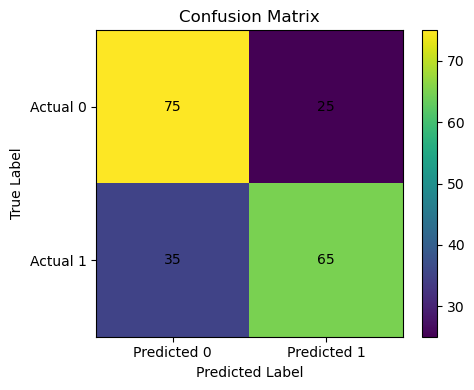

In [4]:
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()